# Rainbow book P&L attribution — the 21-day crash lift in the hedge target

The canonical attribution (`rainbow_attribution.ipynb`) marks, bumps and hedges
the daily-sold rainbow book under the Gaussian copula on the 5-day correlation
matrix. This notebook re-runs the same driver (`rainbow_attribution_ss`, same
book, surfaces, 512-path CRN Sobol standard, seed) with **one change**: the
copula is the one-parameter **crash lift** of `docs/crash_lift_21d.md` —
Andersen–Sidenius loadings that rise by λ = 0.247 below one sigma of the common
market factor, unconditional level re-matched to the same 5-day matrix, implied
marginals exact. Every mark, every 1%-bump greek and every hedge delta comes
from that copula (`copula=` on the driver, `sobol_uniforms_profile` in
`rainbow_torch.py`; cache `data/rainbow_attribution_ss_cl.csv` from
`scripts/run_rainbow_attribution.py`, fifth pass).

What to expect, and what is being tested: the crash-lift model prices the sold
spread about 10 bps of notional higher (ATM leg up, cap leg down), so each
vintage is sold at a higher mark. If the model's extra value is a crash reserve,
the desk's delta-hedged line (chart 5 of the canonical notebook, the black
line) should **drift up in calm periods** as that reserve decays through
`theta_gamma`, and **give it back in joint sell-offs** where the crash state
the model charges for is realized. The hypothesis is tested below by splitting
the hedged difference between the two models by regime.

Two caveats on reading differences. The two runs are not common-random-number
with each other (the Gaussian path draws 3 normals per path, the profile path 4
uniforms), so day-level differences carry ~\$1k of sampling noise against a
\$94k hedged daily std; cumulative noise stays bounded (each vintage settles at
intrinsic) at a few \$k. And the sold premium is model-dependent in this test
book — the vintage is sold at the model's own mark — so the raw `pl` total
moves by the full premium difference; the desk view below, which takes out the
delta and the deterministic carry, is the one to read.

Component definitions are those of the canonical notebook. Analysis-only; the
GPU pass took 987 s in this run (a CPU calibration job shared the machine;
the Gaussian pass runs in 515 s).

In [1]:
import time
T0 = time.time()
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
       "#6250d6", "#e34948"]
g = pd.read_csv("data/rainbow_attribution_ss.csv", parse_dates=["date"],
                index_col="date")                       # Gaussian 5d (canonical)
c = pd.read_csv("data/rainbow_attribution_ss_cl.csv", parse_dates=["date"],
                index_col="date")                       # crash lift 21d
assert g.index.equals(c.index) and (g["n_pos"] == c["n_pos"]).all()
d = c - g                                               # crash lift minus Gaussian
NAMES = ("spx", "sx5e", "hsi")
prem_bps = d["premium"] / 1e6 * 1e4
print(f"{len(c)} date pairs, {c.index[0].date()} -> {c.index[-1].date()}, "
      f"book {c['n_pos'].iloc[-1]} positions")
print(f"premium sold: Gaussian ${g['premium'].sum() / 1e6:.2f}M, crash lift "
      f"${c['premium'].sum() / 1e6:.2f}M (+${d['premium'].sum() / 1e6:.2f}M = "
      f"{prem_bps.mean():+.1f} bps of notional per contract on average, "
      f"range {prem_bps.min():+.1f}..{prem_bps.max():+.1f})")
print(f"final mark: Gaussian ${g['mark'].iloc[-1] / 1e6:.2f}M, crash lift "
      f"${c['mark'].iloc[-1] / 1e6:.2f}M")

1968 date pairs, 2018-12-28 -> 2026-07-31, book 259 positions
premium sold: Gaussian $95.95M, crash lift $97.71M (+$1.75M = +8.9 bps of notional per contract on average, range -2.0..+22.4)
final mark: Gaussian $-20.64M, crash lift $-20.87M


             Gaussian $M  crash lift $M  difference $M  std Gaussian $k  std crash lift $k
pl                -65.71         -64.18           1.53           676.82             681.73
eq                -56.90         -56.54           0.36           675.13             681.59
eq_delta          -52.12         -52.23          -0.11           683.69             690.46
eq_gamma           -8.00          -7.98           0.02            34.84              35.72
eq_xgamma           3.20           3.45           0.25            30.82              31.78
eq_resid            0.03           0.23           0.20            14.02              14.00
vol                -0.32          -0.83          -0.52            61.80              63.14
vol_spx            -0.76          -0.87          -0.11            38.45              39.31
vol_sx5e            0.68           0.40          -0.28            29.30              29.84
vol_hsi            -0.47          -0.56          -0.09            16.55              16.39

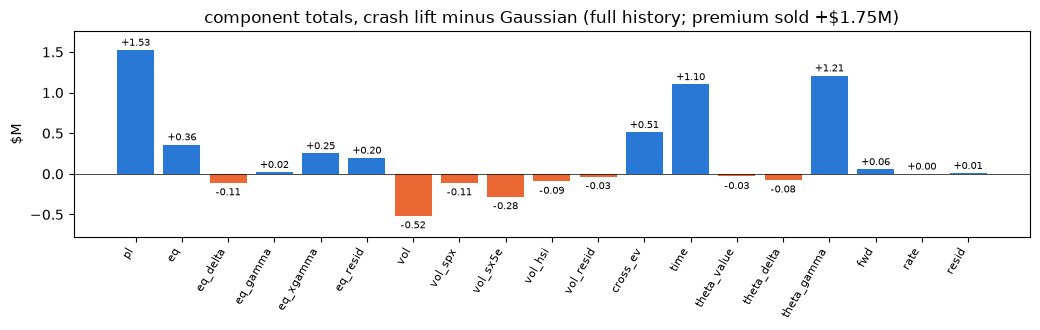

In [2]:
MAIN = ["pl", "eq", "eq_delta", "eq_gamma", "eq_xgamma", "eq_resid",
        "vol", "vol_spx", "vol_sx5e", "vol_hsi", "vol_resid", "cross_ev",
        "time", "theta_value", "theta_delta", "theta_gamma", "fwd", "rate",
        "resid"]
summ = pd.DataFrame({"Gaussian $M": g[MAIN].sum() / 1e6,
                     "crash lift $M": c[MAIN].sum() / 1e6,
                     "difference $M": d[MAIN].sum() / 1e6,
                     "std Gaussian $k": g[MAIN].std() / 1e3,
                     "std crash lift $k": c[MAIN].std() / 1e3})
print(summ.round(2).to_string())
fig, ax = plt.subplots(figsize=(10.5, 3.4))
dd = d[MAIN].sum() / 1e6
ax.bar(np.arange(len(MAIN)), dd, color=[PAL[0] if v >= 0 else PAL[1] for v in dd])
for i, v in enumerate(dd):
    ax.annotate(f"{v:+.2f}", (i, v), ha="center", fontsize=7,
                xytext=(0, 3 if v >= 0 else -9), textcoords="offset points")
ax.set_xticks(np.arange(len(MAIN)))
ax.set_xticklabels(MAIN, rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="k", lw=0.5)
ax.set_ylim(dd.min() * 1.5, dd.max() * 1.15)
ax.set(ylabel="$M", title="component totals, crash lift minus Gaussian "
                          "(full history; premium sold +$%.2fM)" % (d["premium"].sum() / 1e6))
plt.tight_layout()

Reading the totals. The raw `pl` is +\$1.53M better under the crash lift,
and the table says where from. Each vintage was sold at the crash-lift mark:
+8.9 bps of notional per contract on average, +\$1.75M over 1,968 sales (range
−2 to +22 bps — the dispersion is the book's moneyness: the lift adds most to
the ATM leg when the spread is at the money and least when it is deep in), of
which \$0.23M is still unreleased in the final live marks. The risk components
move little: `eq_delta` −\$0.11M (the deltas differ by ~1%, §4 below),
`eq_gamma` unchanged, `eq_xgamma` +\$0.25M, `cross_ev` +\$0.51M, `vol`
−\$0.52M (the crash-lift book carries a slightly larger ATM leg, hence more
vega), and **`theta_gamma` +\$1.21M** — the extra model value decays through
the gamma-theta line, which is the mechanism the hypothesis points at. The
left chart below is the same story cumulatively; the right chart shows the
premium booked and the theta that releases it.

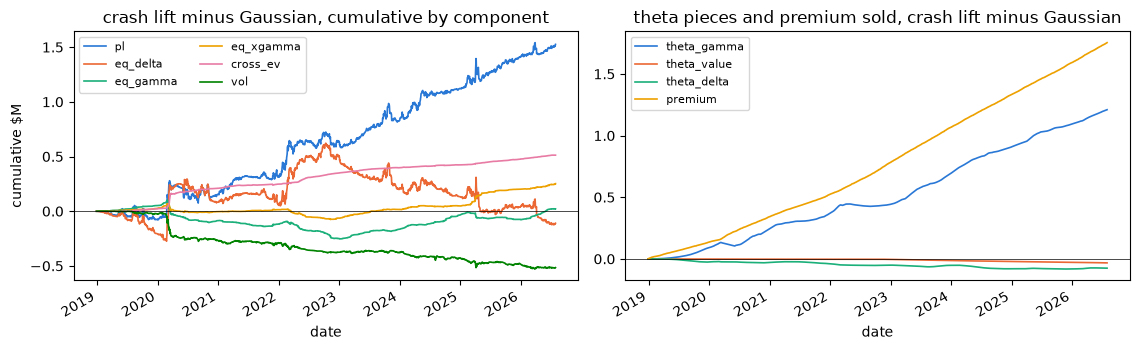

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for k, col in enumerate(["pl", "eq_delta", "eq_gamma", "eq_xgamma", "cross_ev",
                         "vol"]):
    (d[col].cumsum() / 1e6).plot(ax=ax[0], lw=1.2, color=PAL[k], label=col)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].legend(fontsize=8, ncol=2)
ax[0].set(ylabel="cumulative $M",
          title="crash lift minus Gaussian, cumulative by component")
for k, col in enumerate(["theta_gamma", "theta_value", "theta_delta",
                         "premium"]):
    (d[col].cumsum() / 1e6).plot(ax=ax[1], lw=1.2, color=PAL[k], label=col)
ax[1].axhline(0, color="k", lw=0.5)
ax[1].legend(fontsize=8)
ax[1].set(title="theta pieces and premium sold, crash lift minus Gaussian")
plt.tight_layout()

## The desk view — chart 5 with the crash lift

Same definition as the canonical notebook: `pl − eq_delta − theta_value −
theta_delta`, each model hedged with **its own** sticky-strike deltas and its
own carry lines. Solid black is the crash-lift book, dashed grey the Gaussian
book from the canonical cache; the coloured lines decompose the crash-lift
book exactly as chart 5 does (gamma netted against theta, vol, cross_ev, fwd,
other). The lower panel is the difference between the two black lines.

                total $M  std $k  median $  skew  worst day $M  worst-to-date $M
Gaussian 5d       -11.51   94.05  -2467.25 -6.22         -1.47            -11.51
crash lift 21d     -9.77   96.42  -1889.69 -6.46         -1.57             -9.77
difference          1.74    4.38    705.60 -6.25         -0.10             -0.07
market-price view (net of the extra premium): ends -0.01M, median level -0.25M, min -0.60M on 2022-12-12, max +0.13M on 2020-02-26; unreleased reserve on the live book at the end = final mark difference +0.23M
gamma net of theta: Gaussian -4.33M, crash lift -2.84M (theta_gamma +0.48 -> +1.69M, eq_gamma -8.00 -> -7.98M, eq_xgamma +3.20 -> +3.45M)


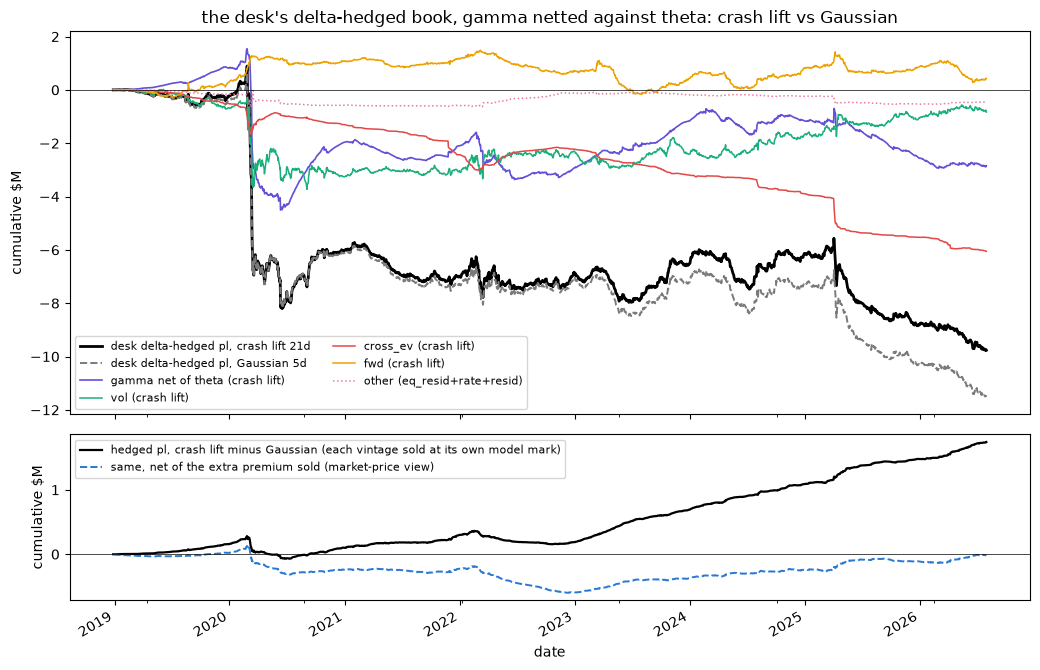

In [4]:
def desk(r):
    return r["pl"] - r[["eq_delta", "theta_value", "theta_delta"]].sum(axis=1)
hg, hc = desk(g), desk(c)
dh = hc - hg
def other(r, h):
    return h - r[["theta_gamma", "eq_gamma", "eq_xgamma", "vol", "cross_ev",
                  "fwd"]].sum(axis=1)
gnet = c[["theta_gamma", "eq_gamma", "eq_xgamma"]].sum(axis=1)
fig, ax = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1.3]})
(hc.cumsum() / 1e6).plot(ax=ax[0], color="k", lw=2,
                         label="desk delta-hedged pl, crash lift 21d")
(hg.cumsum() / 1e6).plot(ax=ax[0], color="#7a7a7a", lw=1.4, ls="--",
                         label="desk delta-hedged pl, Gaussian 5d")
(gnet.cumsum() / 1e6).plot(ax=ax[0], color=PAL[6], lw=1.2,
                           label="gamma net of theta (crash lift)")
for col, k in [("vol", 2), ("cross_ev", 7), ("fwd", 3)]:
    (c[col].cumsum() / 1e6).plot(ax=ax[0], color=PAL[k], lw=1.1,
                                 label=f"{col} (crash lift)")
(other(c, hc).cumsum() / 1e6).plot(ax=ax[0], color=PAL[4], lw=1.1, ls=":",
                                   label="other (eq_resid+rate+resid)")
ax[0].axhline(0, color="k", lw=0.5)
ax[0].legend(fontsize=8, ncol=2)
ax[0].set(ylabel="cumulative $M",
          title="the desk's delta-hedged book, gamma netted against theta: "
                "crash lift vs Gaussian")
(dh.cumsum() / 1e6).plot(ax=ax[1], color="k", lw=1.6,
                         label="hedged pl, crash lift minus Gaussian "
                               "(each vintage sold at its own model mark)")
dfix = dh - d["premium"]          # the extra premium taken out on its sale date
(dfix.cumsum() / 1e6).plot(ax=ax[1], color=PAL[0], lw=1.4, ls="--",
                           label="same, net of the extra premium sold "
                                 "(market-price view)")
ax[1].axhline(0, color="k", lw=0.5)
ax[1].legend(fontsize=8)
ax[1].set(ylabel="cumulative $M")
plt.tight_layout()
stats = lambda h: [h.sum() / 1e6, h.std() / 1e3, h.median(), h.skew(),
                   h.min() / 1e6, h.cumsum().min() / 1e6]
print(pd.DataFrame([stats(hg), stats(hc), stats(dh)],
                   index=["Gaussian 5d", "crash lift 21d", "difference"],
                   columns=["total $M", "std $k", "median $", "skew",
                            "worst day $M", "worst-to-date $M"])
      .round(2).to_string())
cf = dfix.cumsum()
print(f"market-price view (net of the extra premium): ends {cf.iloc[-1] / 1e6:+.2f}M, "
      f"median level {cf.median() / 1e6:+.2f}M, min {cf.min() / 1e6:+.2f}M on "
      f"{cf.idxmin().date()}, max {cf.max() / 1e6:+.2f}M on {cf.idxmax().date()}; "
      f"unreleased reserve on the live book at the end = final mark difference "
      f"{-d['mark'].iloc[-1] / 1e6:+.2f}M")
gn = lambda r: r[["theta_gamma", "eq_gamma", "eq_xgamma"]].sum(axis=1)
print(f"gamma net of theta: Gaussian {gn(g).sum() / 1e6:+.2f}M, crash lift "
      f"{gn(c).sum() / 1e6:+.2f}M (theta_gamma {g['theta_gamma'].sum() / 1e6:+.2f} "
      f"-> {c['theta_gamma'].sum() / 1e6:+.2f}M, eq_gamma "
      f"{g['eq_gamma'].sum() / 1e6:+.2f} -> {c['eq_gamma'].sum() / 1e6:+.2f}M, "
      f"eq_xgamma {g['eq_xgamma'].sum() / 1e6:+.2f} -> "
      f"{c['eq_xgamma'].sum() / 1e6:+.2f}M)")

**The black line does drift up.** The crash-lift book's desk delta-hedged
P&L ends at −\$9.77M against −\$11.51M, +\$1.74M, and the lower panel shows
the drift is steady through the calm years — 2023–2026 above all, where the
book is deep in the money and the sold spreads decay — with two give-backs:
the COVID crash (the difference falls \$0.35M from its February 2020 peak to
the summer trough) and the second half of 2022. Daily risk moves the other
way, slightly: std \$94.1k → \$96.4k, skew −6.2 → −6.5, worst day −\$1.47M →
−\$1.57M. The crash-lift marks are a little more sensitive on the days that
hurt, which is what a model holding more value in the crash state does.

The two lines of the lower panel are two accounting views of the same runs.
The solid line is the raw difference: in this test book each vintage is sold
at the model's own mark, so the crash lift collects +\$1.75M more premium and
the hedged difference ends at +\$1.74M — almost the whole reserve was kept.
The dashed line removes the extra premium on each sale date, the view a desk
selling at a *market* price would see: both books book the same cash, the
crash-lift book marks the new vintage ~9 bps higher on day one (a day-one
loss relative to the Gaussian book) and releases it through `theta_gamma`
over the life. That line ends at −\$0.01M — every expired vintage has the
same payoff, and the live book's unreleased reserve (+\$0.23M) is offset by
the small delta-hedge and carry differences — and its shape is the *timing*
of recognition. It sits around −\$0.25M (the reserve held on the live book),
falls to −\$0.60M by December 2022 as that year's sell-offs consume part of
the reserve while the reserve itself grows (the spreads sold from 2022 on
carry +10–11 bps each against +5–8 bps in 2019–21), and recovers through
2023–2026 as those vintages release it. The drift up in calm periods is the
release of the reserve booked at sale; the dips are the stress episodes
consuming part of it.

                                  days  hedged Gaussian $M  hedged crash lift $M  difference $M  difference $/day
calm days (every |ret| <= 2%)   1542.0               -0.68                  0.99           1.67           1083.62
big-move days (any |ret| > 2%)   426.0              -10.83                -10.75           0.07            168.05
    of which the COVID window     32.0               -6.52                 -6.73          -0.21          -6435.10
all days                        1968.0              -11.51                 -9.77           1.74            885.44


reserve booked at sale: +891 $/day on average (+8.9 bps per contract) vs released: calm days +1,084 $/day, big-move days +168 $/day, COVID window -6,435 $/day
calm-day drift +1,084 $/day over 1542 days = +1.67M | big-move days +0.07M over 426 days | monthly slope +2.0 $k per 1% market move, intercept +17.5 $k/month, corr +0.25


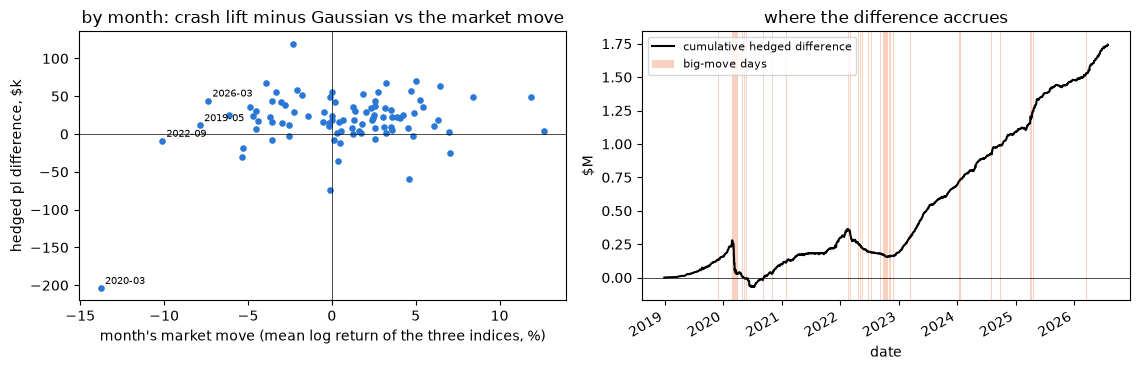

In [5]:
big = c[[f"ret_{n}" for n in NAMES]].abs().max(axis=1) > 0.02
covid = (c.index >= "2020-02-20") & (c.index <= "2020-04-03")
def split(mask, name):
    mask = np.asarray(mask)
    return pd.Series({"days": int(mask.sum()),
                      "hedged Gaussian $M": hg[mask].sum() / 1e6,
                      "hedged crash lift $M": hc[mask].sum() / 1e6,
                      "difference $M": dh[mask].sum() / 1e6,
                      "difference $/day": dh[mask].mean()}, name=name)
tab = pd.concat([split(~big, "calm days (every |ret| <= 2%)"),
                 split(big, "big-move days (any |ret| > 2%)"),
                 split(covid, "    of which the COVID window"),
                 split(np.ones(len(c), bool), "all days")], axis=1).T
print(tab.round(2).to_string())
m = pd.DataFrame({"diff": dh,
                  "mkt": np.log1p(c[[f"ret_{n}" for n in NAMES]]).mean(axis=1)}
                 ).resample("ME").sum()
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].scatter(100 * m["mkt"], m["diff"] / 1e3, s=14, color=PAL[0])
for dt, row in m.iterrows():
    if abs(row["diff"]) > 120e3 or row["mkt"] < -0.07:
        ax[0].annotate(dt.strftime("%Y-%m"), (100 * row["mkt"], row["diff"] / 1e3),
                       fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].axhline(0, color="k", lw=0.5)
ax[0].axvline(0, color="k", lw=0.5)
ax[0].set(xlabel="month's market move (mean log return of the three indices, %)",
          ylabel="hedged pl difference, $k",
          title="by month: crash lift minus Gaussian vs the market move")
cum = dh.cumsum() / 1e6
cum.plot(ax=ax[1], color="k", lw=1.5, label="cumulative hedged difference")
ymin, ymax = cum.min() - 0.1, cum.max() + 0.1
ax[1].fill_between(c.index, ymin, ymax, where=big.values, color=PAL[1],
                   alpha=0.3, lw=0, label="big-move days")
ax[1].set_ylim(ymin, ymax)
ax[1].axhline(0, color="k", lw=0.5)
ax[1].legend(fontsize=8)
ax[1].set(ylabel="$M", title="where the difference accrues")
plt.tight_layout()
booked = d["premium"].mean()
print(f"reserve booked at sale: {booked:+,.0f} $/day on average ({d['premium'].mean() / 1e6 * 1e4:+.1f} bps "
      f"per contract) vs released: calm days {dh[~big].mean():+,.0f} $/day, big-move days "
      f"{dh[big].mean():+,.0f} $/day, COVID window {dh[covid].mean():+,.0f} $/day")
slope = np.polyfit(100 * m["mkt"], m["diff"] / 1e3, 1)
print(f"calm-day drift {dh[~big].mean():+,.0f} $/day over {int((~big).sum())} "
      f"days = {dh[~big].sum() / 1e6:+.2f}M | big-move days "
      f"{dh[big].sum() / 1e6:+.2f}M over {int(big.sum())} days | monthly "
      f"slope {slope[0]:+.1f} $k per 1% market move, intercept "
      f"{slope[1]:+.1f} $k/month, corr {np.corrcoef(m['mkt'], m['diff'])[0, 1]:+.2f}")

**Where it accrues.** Splitting by the day's largest index move: on the
1,542 calm days (every |return| ≤ 2%) the crash-lift book out-earns the
Gaussian book by +\$1,084 a day, +\$1.67M in total; on the 426 big-move days
the difference is +\$0.07M in total, and inside the COVID window it is
−\$0.21M (−\$6.4k a day). The reserve is booked at about +\$890 a day (the
average premium difference) and released at +\$1,084 a day in calm markets.
By month the difference is mildly pro-cyclical (slope +\$2.0k per 1% of market
move, correlation +0.25), with March 2020 the one large give-back (−\$200k).

So the shape the hypothesis predicts is there: the reserve decays in calm
months and is partly consumed in the crash months. What is not there is the
proportion — the give-back across the two stress episodes is about a fifth of
the calm-day drift. In this book a realized sell-off hurts both models through
the same gamma on the same spot moves; the crash-lift mark differs from the
Gaussian mark only by how much extra value it holds for the *next* crash, and
the 100/112 cap shelters that difference (the 2026-08-10 verdict: the capped
spread's dependence exposure is small at the money). The reserve is not spent
by a crash; it is spent by time.

COVID window: hedged Gaussian -6.52M, crash lift -6.73M, difference -0.21M (gamma net of theta -4.39 -> -4.52M, cross_ev -0.60 -> -0.47M)
2022: hedged Gaussian +0.26M, crash lift +0.15M, difference -0.11M (gamma net of theta -0.70 -> -0.84M, cross_ev +0.11 -> +0.21M)


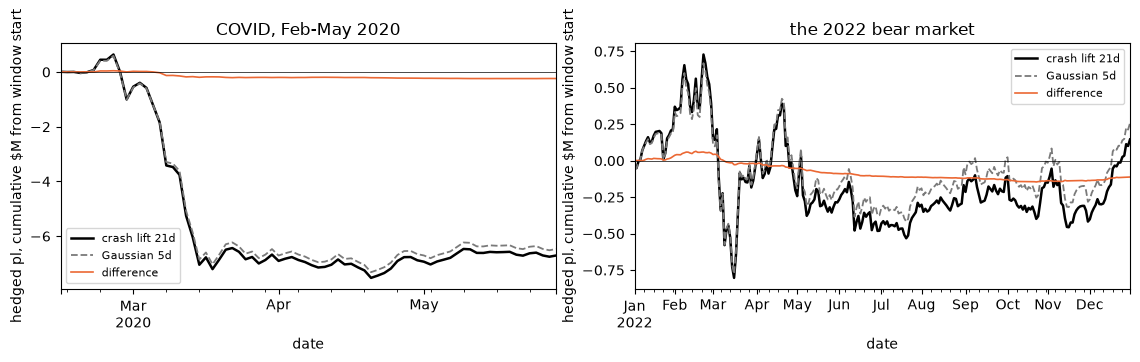

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for a, (lo, hi, ttl) in zip(ax, [("2020-02-14", "2020-05-29", "COVID, Feb-May 2020"),
                                 ("2022-01-03", "2022-12-30", "the 2022 bear market")]):
    w = slice(lo, hi)
    (hc[w].cumsum() / 1e6).plot(ax=a, color="k", lw=1.8, label="crash lift 21d")
    (hg[w].cumsum() / 1e6).plot(ax=a, color="#7a7a7a", lw=1.3, ls="--",
                                label="Gaussian 5d")
    (dh[w].cumsum() / 1e6).plot(ax=a, color=PAL[1], lw=1.2, label="difference")
    a.axhline(0, color="k", lw=0.5)
    a.legend(fontsize=8)
    a.set(ylabel="hedged pl, cumulative $M from window start", title=ttl)
plt.tight_layout()
for lo, hi, ttl in [("2020-02-20", "2020-04-03", "COVID window"),
                    ("2022-01-03", "2022-12-30", "2022")]:
    w = slice(lo, hi)
    print(f"{ttl}: hedged Gaussian {hg[w].sum() / 1e6:+.2f}M, crash lift "
          f"{hc[w].sum() / 1e6:+.2f}M, difference {dh[w].sum() / 1e6:+.2f}M "
          f"(gamma net of theta {gn(g)[w].sum() / 1e6:+.2f} -> "
          f"{gn(c)[w].sum() / 1e6:+.2f}M, cross_ev {g['cross_ev'][w].sum() / 1e6:+.2f} "
          f"-> {c['cross_ev'][w].sum() / 1e6:+.2f}M)")

COVID and 2022 up close. In the COVID window the two books track each other
through the −\$6.5M crash; the crash-lift book loses \$0.21M more (gamma net
of theta −\$4.39M → −\$4.52M, partly offset by `cross_ev` −\$0.60M →
−\$0.47M). In 2022, a year of repeated multi-week sell-offs, the difference
drifts to −\$0.11M by December. Neither episode consumes more than a fraction
of the reserve collected before it.

## The hedge ratio

       median delta ratio (crash lift / Gaussian)           IQR  eq_delta Gaussian $M  eq_delta crash lift $M
index                                                                                                        
spx                                         1.010  0.996..1.020               -33.396                 -33.620
sx5e                                        1.006  0.987..1.020               -16.003                 -16.010
hsi                                         1.004  0.989..1.018                -2.726                  -2.605


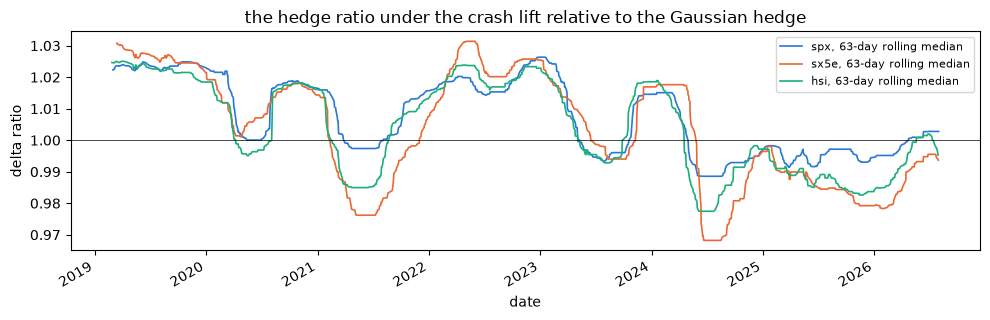

In [7]:
rows = []
for n in NAMES:
    ok = c[f"ret_{n}"].abs() > 0.005
    ratio = c.loc[ok, f"eq_delta_{n}"] / g.loc[ok, f"eq_delta_{n}"]
    rows.append({"index": n,
                 "median delta ratio (crash lift / Gaussian)": ratio.median(),
                 "IQR": f"{ratio.quantile(0.25):.3f}..{ratio.quantile(0.75):.3f}",
                 "eq_delta Gaussian $M": g[f"eq_delta_{n}"].sum() / 1e6,
                 "eq_delta crash lift $M": c[f"eq_delta_{n}"].sum() / 1e6})
print(pd.DataFrame(rows).set_index("index").round(3).to_string())
fig, ax = plt.subplots(figsize=(10, 3.3))
for k, n in enumerate(NAMES):
    ok = c[f"ret_{n}"].abs() > 0.005
    (c.loc[ok, f"eq_delta_{n}"] / g.loc[ok, f"eq_delta_{n}"]).rolling(
        63, min_periods=20).median().plot(ax=ax, lw=1.2, color=PAL[k],
                                          label=f"{n}, 63-day rolling median")
ax.axhline(1, color="k", lw=0.5)
ax.legend(fontsize=8)
ax.set(ylabel="delta ratio",
       title="the hedge ratio under the crash lift relative to the Gaussian hedge")
plt.tight_layout()

The hedge itself barely changes: median delta ratios of 1.010 / 1.006 /
1.004 (SPX / SX5E / HSI) with an interquartile range of about ±2%, and a
63-day rolling median that swings between 0.97 and 1.03 — above one in the
flat and bear phases (2019, 2022–23), below one in the rallies (2021,
2024–25) when the book is deep in the money. This is the ~3% figure measured
on the panel dates in the changelog, now seen through the history, and it is
why `eq_delta` differs by only \$0.11M over \$52M.

## Identities and residual

In [8]:
tay = c[["eq_delta", "eq_gamma", "eq_xgamma", "eq_resid"]].sum(axis=1)
th = c[["theta_value", "theta_delta", "theta_gamma"]].sum(axis=1)
top = c[["eq", "vol", "cross_ev", "time", "fwd", "rate", "resid"]].sum(axis=1)
assert np.allclose(tay, c["eq"], atol=1e-6)
assert np.allclose(th, c["time"], atol=1e-6)
assert np.allclose(top, c["pl"], atol=1e-6)
print(f"identities exact on the crash-lift cache | resid std ${c['resid'].std():,.0f} = "
      f"{c['resid'].std() / c['pl'].std():.2%} of pl std (Gaussian "
      f"{g['resid'].std() / g['pl'].std():.2%}) | eq_resid std ${c['eq_resid'].std():,.0f} "
      f"(Gaussian ${g['eq_resid'].std():,.0f})")

identities exact on the crash-lift cache | resid std $4,234 = 0.62% of pl std (Gaussian 0.61%) | eq_resid std $14,005 (Gaussian $14,020)


## Takeaways

- **The hypothesis holds in shape.** With the 21-day crash lift as the hedge
  target, the desk's delta-hedged line drifts up at +\$1.1k a day on calm
  days (+\$1.67M over 1,542 days) and gives back in the stress episodes
  (COVID −\$0.21M, 2022 −\$0.11M). The drift is `theta_gamma` (+\$1.21M) and
  `cross_ev` (+\$0.51M) releasing the extra value the model holds.
- **Not in proportion.** The give-back is about a fifth of the drift: the
  capped spread's realized stress losses come through the same gamma under
  both models, so the reserve the crash lift charges for (+8.9 bps per
  contract, +\$1.75M) is mostly retained. On this book and sample the
  crash-lift premium is a margin, not a cost that the realized crashes
  recovered.
- **What the +\$1.74M is.** In this test book the sale price is the model's
  own mark, so a higher model price is simply more premium. Under a
  market-set price the same runs show a timing difference that nets to zero
  per vintage: the crash lift defers ~9 bps of day-one P&L into theta
  released over the life — a reserve, which is the role recommended for it
  in `docs/crash_lift_21d.md`.
- **As a hedge target it is marginally worse on daily risk** (std +2.5%,
  skew −6.2 → −6.5, worst day −\$1.47M → −\$1.57M) with deltas within ~1–3%
  of the Gaussian hedge. The recommendation stands: Gaussian 5d as the hedge
  model, crash lift 21d as the valuation/reserve line.
- Attribution quality is identical: residual 0.62% of P&L std (Gaussian
  0.61%), Taylor residual std \$14.0k on both, every identity exact.

In [9]:
print(f"total notebook runtime: {time.time() - T0:.1f}s (analysis-only; the "
      f"crash-lift GPU pass lives in scripts/run_rainbow_attribution.py)")

total notebook runtime: 10.7s (analysis-only; the crash-lift GPU pass lives in scripts/run_rainbow_attribution.py)
